# R3a — Pasos 1 y 2 de la cascada: YOLO + ByteTrack + reglas → ROI

Hasta R2c la zona que veía el supervisor salía de la **anotación** (ROI oráculo). Aquí, por primera vez, la zona la genera el propio sistema:

1. **YOLO** detecta vehículos y personas en cada frame (10 fps).
2. **ByteTrack** les da identidad a lo largo del tiempo (el auto #3 del frame 10 es el mismo #3 del frame 11).
3. **Reglas** sobre las trayectorias: *contacto* entre dos tracks que se venían acercando y frenan después, o *frenado/giro brusco* de uno solo. Dan un **score**, una **alerta** y la **caja del evento**.

*Analogía:* YOLO + ByteTrack es el sensor de movimiento de una alarma de casa (barato, siempre prendido); las reglas deciden si ese movimiento "parece raro"; el LoRA (R3b) es el guardia que solo revisa la cámara que la alarma le señala.

**Qué mide este notebook (sobre las mismas 60 ventanas de R2c):**
- Latencia real de YOLO en la T4 → ¿cuántas cámaras aguanta una GPU? (el argumento de costo pedía ~1,000 img/s para 100 cámaras).
- El paso 2 como detector por sí solo: AUC del score y alertas.
- Calidad de la ROI generada contra la ROI oráculo (¿el recorte contiene el choque?).
- Guarda `rois_yolo_<huella>.csv` para que **R3b** corra el LoRA con estas zonas.

**Regla de honestidad:** los umbrales de las reglas están fijos *antes* de ver el test (se probaron con trayectorias sintéticas). Si se ajustan mirando estas 60 ventanas, el resultado deja de ser una prueba.

In [ ]:
# ===== 1. Configuración =====
HUELLA = "ebfa594f"                 # experimento de R2c (mismas 60 ventanas)
ARCH_VENTANAS = f"test_roi_lora_{HUELLA}.csv"
DIR_VIDEOS = "/content/datos_roadvision/accident"   # mismo lugar que en R2c

YOLO_PESOS = "yolov8n.pt"           # prueba también yolo11n.pt / yolov8s.pt
FPS_TRACK = 10                      # frames por segundo que ve YOLO (C5 estandarizado a 10 fps en R0)
IMGSZ = 640
CONF = 0.25

# Formato de la columna `roi` de R2c (4 números normalizados). Se confirma con el código de R2c:
#   'xywh'   = (x_izq, y_arriba, ancho, alto)
#   'cxcywh' = (centro_x, centro_y, ancho, alto)
FORMATO_ROI = 'xywh'
FACTOR_RECORTE = 3.0                # recorte cuadrado de 3× la caja…
MIN_LADO = 0.25                     # …con mínimo 25 % del lado corto (igual que R2c)

In [ ]:
# ===== 2. Instalación, Drive y GPU =====
!pip -q install ultralytics lap
import os, glob, json, time, zipfile, subprocess
import numpy as np, pandas as pd, torch
from google.colab import drive
drive.mount('/content/drive')
RAIZ = '/content/drive/MyDrive'
GPU = torch.cuda.is_available()
print('GPU:', torch.cuda.get_device_name(0) if GPU else 'NINGUNA (Entorno → Cambiar tipo → T4)')

def buscar(nombre):
    esperada = f'{RAIZ}/roadvision/resultados_qwen/{nombre}'
    if os.path.exists(esperada): return esperada
    hits = glob.glob(f'{RAIZ}/**/{nombre}', recursive=True)
    assert hits, f'No encontré {nombre} en Drive'
    return hits[0]

ruta_ventanas = buscar(ARCH_VENTANAS)
SALIDA = f'{os.path.dirname(ruta_ventanas)}/r3_{HUELLA}'
os.makedirs(SALIDA, exist_ok=True)
print('ventanas:', ruta_ventanas); print('salida  :', SALIDA)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
ventanas: /content/drive/MyDrive/roadvision/resultados_qwen/test_roi_lora_ebfa594f.csv
salida  : /content/drive/MyDrive/roadvision/resultados_qwen/r3_ebfa594f


In [ ]:
# ===== 3. Las 60 ventanas de R2c =====
v = pd.read_csv(ruta_ventanas)
v['y'] = (v['clase'] == 'positiva').astype(int)
v['roi_oraculo'] = v['roi'].apply(lambda s: tuple(float(x) for x in s.strip('()[] ').split(',')))
v['wid'] = v['video'] + '|' + v['inicio'].round(3).astype(str)
assert v['wid'].is_unique
v['ruta_local'] = v['ruta_rel'].apply(lambda r: os.path.join(DIR_VIDEOS, r))
print(f"{len(v)} ventanas ({v.y.sum()} pos / {(1 - v.y).sum()} neg), {v.video.nunique()} videos")
display(v[['video', 'clase', 'inicio', 'fin', 't_choque', 'tipo_real', 'roi_oraculo']].head())

60 ventanas (30 pos / 30 neg), 30 videos


,video,clase,inicio,fin,t_choque,tipo_real,roi_oraculo
0,QbTAfMWdSN0_00,positiva,6.411179,14.411179,8.583000,t-bone,"(0.3947563621118055, 0.5248460035678482, 0.121..."
1,QbTAfMWdSN0_00,negativa,0.000000,5.583000,8.583000,t-bone,"(0.3947563621118055, 0.5248460035678482, 0.121..."
2,sKJdbm04q6U_00,positiva,5.014127,13.014127,10.333000,single,"(0.1475874681825989, 0.4544486038773149, 0.024..."
3,sKJdbm04q6U_00,negativa,0.000000,7.333000,10.333000,single,"(0.1475874681825989, 0.4544486038773149, 0.024..."
4,Czp_f_DrRB8_00,positiva,6.939491,14.939491,10.916666,sideswipe,"(0.7460244890232796, 0.4419556999900966, 0.055..."


In [ ]:
# ===== 4. Videos: usa los que ya estén; si no, descarga ACCIDENT y extrae solo estos =====
faltan = sorted(set(v.loc[~v.ruta_local.apply(os.path.exists), 'ruta_rel']))
print(f'Videos que faltan: {len(faltan)} de {v.ruta_rel.nunique()}')

if faltan:
    # Credenciales de Kaggle: secretos de Colab (🔑) o kaggle.json en Drive
    try:
        from google.colab import userdata
        for k in ['KAGGLE_USERNAME', 'KAGGLE_KEY', 'KAGGLE_API_TOKEN']:
            try: os.environ[k] = userdata.get(k)
            except Exception: pass
    except ImportError:
        pass
    if not (os.environ.get('KAGGLE_KEY') or os.environ.get('KAGGLE_API_TOKEN')):
        cand = glob.glob(f'{RAIZ}/kaggle.json') + glob.glob(f'{RAIZ}/*/kaggle.json') + glob.glob(f'{RAIZ}/*/*/kaggle.json')
        assert cand, 'No hay credenciales de Kaggle: agrega KAGGLE_USERNAME/KAGGLE_KEY en secretos o sube kaggle.json a Drive'
        os.makedirs('/root/.kaggle', exist_ok=True)
        !cp "{cand[0]}" /root/.kaggle/kaggle.json && chmod 600 /root/.kaggle/kaggle.json
    zips = glob.glob('/content/accident_zip/*.zip')
    if not zips:
        !kaggle datasets download picekl/accident -p /content/accident_zip
        zips = glob.glob('/content/accident_zip/*.zip')
    with zipfile.ZipFile(zips[0]) as z:
        nombres = z.namelist()
        for rel in faltan:
            m = [n for n in nombres if n == rel or n.endswith('/' + rel)]
            assert m, f'{rel} no está en el ZIP'
            destino = os.path.join(DIR_VIDEOS, rel)
            os.makedirs(os.path.dirname(destino), exist_ok=True)
            with z.open(m[0]) as src, open(destino, 'wb') as dst:
                dst.write(src.read())
    print('Extraídos ✔')
assert v.ruta_local.apply(os.path.exists).all()

Videos que faltan: 30 de 30
Dataset URL: https://www.kaggle.com/datasets/picekl/accident
License(s): CC-BY-NC-SA-4.0
100% 15.6G/15.6G [04:00<00:00, 69.8MB/s]

Extraídos ✔


In [ ]:
# ===== 5. Paso 1: lectura de ventana + YOLO + ByteTrack =====
import cv2, time, numpy as np, pandas as pd

CLASES = {0: 'persona', 1: 'bici', 2: 'auto', 3: 'moto', 5: 'autobus', 7: 'camion'}


def leer_ventana(ruta, inicio, fin, fps_obj):
    """Lectura secuencial (como en R2c): decodifica todo y se queda con 1 de cada k frames."""
    cap = cv2.VideoCapture(ruta)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    paso = max(1, round(fps / fps_obj))
    i0, i1 = int(round(inicio * fps)), int(round(fin * fps))
    cap.set(cv2.CAP_PROP_POS_FRAMES, i0)
    frames, ts, i = [], [], i0
    while i < i1:
        ok, f = cap.read()
        if not ok:
            break
        if (i - i0) % paso == 0:
            frames.append(f)
            ts.append(i / fps)
        i += 1
    cap.release()
    return frames, np.array(ts), fps


def reiniciar_tracker(modelo):
    p = getattr(modelo, 'predictor', None)
    if p is not None and hasattr(p, 'trackers'):
        for tr in p.trackers:
            tr.reset()


def precision_kw(gpu):
    """fp16 en GPU. Ultralytics ≥ 8.4 cambió `half=True` por `quantize=16`."""
    from ultralytics.cfg import DEFAULT_CFG_DICT
    if not gpu:
        return {}
    return {'quantize': 16} if 'quantize' in DEFAULT_CFG_DICT else {'half': True}


def trackear(modelo, frames, ts, imgsz=640, conf=0.25, prec=None, tracker='bytetrack.yaml'):
    """Devuelve DataFrame de tracks (coordenadas normalizadas) y el tiempo de cómputo por frame."""
    reiniciar_tracker(modelo)
    filas, tiempos = [], []
    for f, t in zip(frames, ts):
        t0 = time.perf_counter()
        r = modelo.track(f, persist=True, tracker=tracker, classes=list(CLASES), conf=conf,
                         imgsz=imgsz, verbose=False, **(prec or {}))[0]
        tiempos.append(time.perf_counter() - t0)
        b = r.boxes
        if b is None or b.id is None:
            continue
        xyxyn = b.xyxyn.cpu().numpy()
        for (x1, y1, x2, y2), tid, c, p in zip(xyxyn, b.id.int().cpu().numpy(),
                                               b.cls.int().cpu().numpy(), b.conf.cpu().numpy()):
            filas.append((t, int(tid), int(c), float(p), x1, y1, x2, y2))
    tr = pd.DataFrame(filas, columns=['t', 'tid', 'cls', 'conf', 'x1', 'y1', 'x2', 'y2'])
    return tr, np.array(tiempos)

from ultralytics import YOLO
modelo = YOLO(YOLO_PESOS)
PREC = precision_kw(GPU)
print('Precisión:', PREC or 'fp32')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Precisión: {'quantize': 16}


In [ ]:
# ===== 6. Paso 2: reglas =====
# Entrada: DataFrame de tracks de UNA ventana con columnas
#   t (s), tid, cls, conf, x1, y1, x2, y2   (coordenadas normalizadas 0–1)
# Salida: dict con score, alerta, caja ROI (x1,y1,x2,y2 normalizada), t_evento, motivo
import numpy as np
import pandas as pd

REGLAS = dict(
    MIN_PUNTOS=4,        # un track necesita ≥ 4 detecciones para tener velocidad
    SUAVIZADO=3,         # mediana móvil de 3 frames sobre el centro
    V_MIN=0.6,           # velocidad mínima "en movimiento" (diagonales de la caja por segundo)
    VENTANA_FRENO=1.0,   # s: un choque detiene en < 1 s; frenar en semáforo tarda 2–3 s
    CAIDA_FRENO=0.6,     # frenado brusco: la velocidad cae ≥ 60 %…
    DECEL_MIN=0.9,       # …y además baja ≥ 0.9 diagonales/s dentro de VENTANA_FRENO (frenar suave no cuenta)
    GIRO_MIN=50,         # grados: cambio brusco de dirección
    IOU_CONTACTO=0.03,   # traslape mínimo entre dos cajas para "contacto"
    ACERC_MIN=0.8,       # acercamiento: la distancia (en diagonales) baja a este ritmo por s
    PESO_SOLO=0.5,       # un vehículo solo (frenado/giro sin contacto) pesa menos que un par
    UMBRAL_ALERTA=0.45,  # score ≥ esto → el paso 2 dispara alerta
)


def _iou(a, b):
    x1, y1 = np.maximum(a[..., 0], b[..., 0]), np.maximum(a[..., 1], b[..., 1])
    x2, y2 = np.minimum(a[..., 2], b[..., 2]), np.minimum(a[..., 3], b[..., 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    ar = lambda c: (c[..., 2] - c[..., 0]) * (c[..., 3] - c[..., 1])
    return inter / np.maximum(ar(a) + ar(b) - inter, 1e-9)


def cinematica(tr, R=REGLAS):
    """Por track: centro suavizado, velocidad (en diagonales/s), dirección."""
    out = {}
    for tid, g in tr.sort_values('t').groupby('tid'):
        if len(g) < R['MIN_PUNTOS']:
            continue
        g = g.copy()
        g['cx'] = ((g.x1 + g.x2) / 2).rolling(R['SUAVIZADO'], center=True, min_periods=1).median()
        g['cy'] = ((g.y1 + g.y2) / 2).rolling(R['SUAVIZADO'], center=True, min_periods=1).median()
        g['diag'] = np.hypot(g.x2 - g.x1, g.y2 - g.y1).rolling(5, center=True, min_periods=1).median()
        dt = g.t.diff().replace(0, np.nan)
        vx, vy = g.cx.diff() / dt, g.cy.diff() / dt
        g['v'] = (np.hypot(vx, vy) / g.diag).rolling(R['SUAVIZADO'], center=True, min_periods=1).mean()
        g['ang'] = np.degrees(np.arctan2(vy, vx))
        out[tid] = g.reset_index(drop=True)
    return out


def eventos_individuales(cin, R=REGLAS):
    """Frenado brusco y giro brusco de un solo track."""
    ev = []
    for tid, g in cin.items():
        t, v, ang = g.t.values, g.v.values, g.ang.values
        for i in range(len(g)):
            if not np.isfinite(v[i]) or v[i] < R['V_MIN']:
                continue
            fut = (t > t[i]) & (t <= t[i] + R['VENTANA_FRENO'])
            if not fut.any():
                continue
            vmin = np.nanmin(v[fut])
            caida = 1 - vmin / v[i]
            if caida >= R['CAIDA_FRENO'] and (v[i] - vmin) >= R['DECEL_MIN']:
                j = np.where(fut)[0][np.nanargmin(v[fut])]
                ev.append(dict(tipo='frenado', tids=(tid,), t=t[j], fuerza=caida, i=j))
            a_fut = ang[fut & (v >= R['V_MIN'])]   # dirección solo cuando sí se mueve (quieto = ruido)
            if len(a_fut) and np.isfinite(ang[i]):
                giro = np.abs((a_fut - ang[i] + 180) % 360 - 180).max()
                if giro >= R['GIRO_MIN']:
                    ev.append(dict(tipo='giro', tids=(tid,), t=t[i], fuerza=min(giro / 90, 1.0), i=i))
    return ev


def eventos_pares(cin, R=REGLAS):
    """Contacto entre dos tracks (traslape) que se venían acercando."""
    ev = []
    tids = list(cin)
    for a in range(len(tids)):
        for b in range(a + 1, len(tids)):
            ga, gb = cin[tids[a]], cin[tids[b]]
            m = ga.merge(gb, on='t', suffixes=('_a', '_b'))
            if len(m) < 2:
                continue
            ca = m[['x1_a', 'y1_a', 'x2_a', 'y2_a']].values
            cb = m[['x1_b', 'y1_b', 'x2_b', 'y2_b']].values
            iou = _iou(ca, cb)
            toca = np.where(iou >= R['IOU_CONTACTO'])[0]
            if not len(toca):
                continue
            k = int(toca[0])   # inicio del contacto (no el máximo: después del choque siguen pegados)
            iou_max = float(iou[k:k + 10].max())
            diag = (m.diag_a + m.diag_b).values / 2
            dist = np.hypot(m.cx_a - m.cx_b, m.cy_a - m.cy_b).values / diag
            antes = m.t.values <= m.t.values[k]
            if antes.sum() >= 2:
                tt, dd = m.t.values[antes], dist[antes]
                acerc = max(0.0, -(np.polyfit(tt, dd, 1)[0]))   # cuánto bajó la distancia por s
            else:
                acerc = 0.0
            # Dos autos que ya estaban pegados (fila en semáforo) no se acercan → acerc ≈ 0
            f_acerc = min(acerc / R['ACERC_MIN'], 1.0)
            # Frenado justo después del contacto: velocidad (del más rápido) antes vs después
            tk, tm = m.t.values[k], m.t.values
            vmx = np.fmax(m.v_a.values, m.v_b.values)
            pre = (tm >= tk - 1.0) & (tm <= tk)
            post = (tm >= tk + 0.5) & (tm <= tk + 0.5 + R['VENTANA_FRENO'])
            if pre.any() and post.any() and np.nanmedian(vmx[pre]) > 0:
                f_freno = float(np.clip(1 - np.nanmedian(vmx[post]) / np.nanmedian(vmx[pre]), 0, 1))
            else:
                f_freno = 0.0
            fuerza = min(1.0, iou_max / 0.15) * (0.5 * f_acerc + 0.5 * f_freno)
            if fuerza > 0:
                ev.append(dict(tipo='contacto', tids=(tids[a], tids[b]), t=m.t.values[k],
                               fuerza=fuerza, iou=iou_max, acerc=f_acerc, freno=f_freno))
    return ev


def caja_evento(cin, e):
    cajas = []
    for tid in e['tids']:
        g = cin[tid]
        i = int(np.argmin(np.abs(g.t.values - e['t'])))
        cajas.append(g.loc[i, ['x1', 'y1', 'x2', 'y2']].values.astype(float))
    c = np.array(cajas)
    return np.r_[c[:, 0].min(), c[:, 1].min(), c[:, 2].max(), c[:, 3].max()]


def caja_respaldo(tr):
    """Sin eventos: zona con más movimiento de detecciones; si no hay nada, centro de la imagen."""
    if len(tr) == 0:
        return np.array([0.375, 0.375, 0.625, 0.625]), 'centro'
    cx, cy = (tr.x1 + tr.x2) / 2, (tr.y1 + tr.y2) / 2
    H, _, _ = np.histogram2d(cy, cx, bins=6, range=[[0, 1], [0, 1]])
    iy, ix = np.unravel_index(np.argmax(H), H.shape)
    cel = tr[(cx // (1 / 6)).clip(0, 5).eq(ix) & (cy // (1 / 6)).clip(0, 5).eq(iy)]
    return np.r_[cel.x1.min(), cel.y1.min(), cel.x2.max(), cel.y2.max()], 'densidad'


def evaluar_ventana(tr, R=REGLAS):
    cin = cinematica(tr, R)
    ev = [dict(e, score=e['fuerza']) for e in eventos_pares(cin, R)]
    ev += [dict(e, score=R['PESO_SOLO'] * e['fuerza']) for e in eventos_individuales(cin, R)]
    if ev:
        e = max(ev, key=lambda x: x['score'])
        caja, fuente = caja_evento(cin, e), e['tipo']
        score, t_ev, n = e['score'], e['t'], len(ev)
    else:
        caja, fuente = caja_respaldo(tr)
        score, t_ev, n = 0.0, np.nan, 0
    return dict(score=float(score), alerta=bool(score >= R['UMBRAL_ALERTA']), fuente=fuente,
                t_evento=t_ev, n_eventos=n, n_tracks=len(cin),
                x1=caja[0], y1=caja[1], x2=caja[2], y2=caja[3])

print('Umbrales (fijos antes de ver el test):'); print(pd.Series(REGLAS).to_string())

Umbrales (fijos antes de ver el test):
MIN_PUNTOS        4.00
SUAVIZADO         3.00
V_MIN             0.60
VENTANA_FRENO     1.00
CAIDA_FRENO       0.60
DECEL_MIN         0.90
GIRO_MIN         50.00
IOU_CONTACTO      0.03
ACERC_MIN         0.80
PESO_SOLO         0.50
UMBRAL_ALERTA     0.45


## 7. Latencia real de YOLO en la T4

Tres mediciones con frames reales de C5:
- **Por frame, lote 1**: lo que tarda una cámara sola (latencia).
- **Por lote (8/16/32)**: varias cámaras juntas en la GPU (rendimiento, imágenes por segundo).
- **Con ByteTrack**: el costo real del paso 1 por frame (se mide en la celda 8).

In [ ]:
# ===== 7. Benchmark =====
fr, _, _ = leer_ventana(v.ruta_local.iloc[0], 0, 8, FPS_TRACK)
fr = (fr * (64 // len(fr) + 1))[:64]
print('Resolución de entrada:', fr[0].shape)
for _ in range(10): modelo.predict(fr[0], imgsz=IMGSZ, verbose=False, **PREC)   # calentamiento

def medir(lote, n_rep):
    if GPU: torch.cuda.synchronize()
    t0 = time.perf_counter()
    for i in range(n_rep):
        modelo.predict(fr[(i * lote) % 32:(i * lote) % 32 + lote], imgsz=IMGSZ, verbose=False,
                       classes=list(CLASES), conf=CONF, **PREC)
    if GPU: torch.cuda.synchronize()
    return (time.perf_counter() - t0) / (n_rep * lote)

bench = []
for lote in [1, 8, 16, 32]:
    s = medir(lote, 200 if lote == 1 else 20)
    bench.append(dict(lote=lote, ms_por_imagen=1000 * s, img_por_s=1 / s, camaras_10fps=1 / s / FPS_TRACK))
bench = pd.DataFrame(bench).round(1)
display(bench)
mejor = bench.img_por_s.max()
print(f'Para 100 cámaras a {FPS_TRACK} fps se necesitan {100 * FPS_TRACK} img/s → '
      f'{100 * FPS_TRACK / mejor:.2f} T4 solo para YOLO (con el mejor lote).')
print('Nota: incluye pre y posproceso de ultralytics; no incluye decodificar el video.')

Resolución de entrada: (720, 960, 3)


,lote,ms_por_imagen,img_por_s,camaras_10fps
0,1,13.3,75.3,7.5
1,8,5.8,173.7,17.4
2,16,5.1,197.1,19.7
3,32,4.8,209.4,20.9


Para 100 cámaras a 10 fps se necesitan 1000 img/s → 4.78 T4 solo para YOLO (con el mejor lote).
Nota: incluye pre y posproceso de ultralytics; no incluye decodificar el video.


In [ ]:
# ===== 8. Correr YOLO + ByteTrack en las 60 ventanas (con caché en Drive) =====
cache = f'{SALIDA}/tracks_{os.path.splitext(os.path.basename(YOLO_PESOS))[0]}_{FPS_TRACK}fps.parquet'
if os.path.exists(cache):
    tracks = pd.read_parquet(cache); t_frames = None
    print('Tracks leídos de caché:', cache)
else:
    todos, t_frames, t_lect = [], [], []
    for k, r in enumerate(v.itertuples()):
        t0 = time.perf_counter()
        frames, ts, fps = leer_ventana(r.ruta_local, r.inicio, r.fin, FPS_TRACK)
        t_lect.append(time.perf_counter() - t0)
        tr, tt = trackear(modelo, frames, ts, imgsz=IMGSZ, conf=CONF, prec=PREC)
        tr['wid'] = r.wid
        todos.append(tr); t_frames.extend(tt[1:])
        if k % 10 == 0:
            print(f'{k:2d}/{len(v)}  {len(frames)} frames  {tr.tid.nunique()} tracks  '
                  f'{1000 * np.mean(tt[1:]):.1f} ms/frame')
    tracks = pd.concat(todos, ignore_index=True)
    tracks.to_parquet(cache)
    t_frames = np.array(t_frames)
    print(f'\nYOLO + ByteTrack: {1000 * t_frames.mean():.1f} ms/frame (p95 {1000 * np.percentile(t_frames, 95):.1f}) '
          f'→ {1 / t_frames.mean():.0f} frames/s en lote 1')
    print(f'Lectura de video: {np.mean(t_lect):.2f} s por ventana')
print(f'{len(tracks):,} detecciones, {tracks.groupby("wid").tid.nunique().mean():.1f} tracks por ventana')
print(tracks.cls.map(CLASES).value_counts().to_string())

 0/60  116 frames  20 tracks  12.0 ms/frame
10/60  71 frames  4 tracks  11.2 ms/frame
20/60  60 frames  2 tracks  13.9 ms/frame
30/60  112 frames  9 tracks  12.0 ms/frame
40/60  120 frames  2 tracks  9.9 ms/frame
50/60  120 frames  15 tracks  11.4 ms/frame

YOLO + ByteTrack: 12.0 ms/frame (p95 18.0) → 83 frames/s en lote 1
Lectura de video: 0.61 s por ventana
11,410 detecciones, 10.1 tracks por ventana
cls
auto       9076
camion     1015
persona     797
autobus     514
moto          8


/tmp/ipykernel_1366/815561911.py:18: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  tracks = pd.concat(todos, ignore_index=True)


In [ ]:
# ===== 9. Paso 2 en cada ventana → score, alerta y caja =====
filas = []
for r in v.itertuples():
    tr = tracks[tracks.wid == r.wid]
    res = evaluar_ventana(tr)
    res['wid'] = r.wid
    filas.append(res)
p2 = pd.DataFrame(filas)
d = v.merge(p2, on='wid')

# Caja YOLO → mismo formato que la columna `roi` de R2c (para que R3b solo cambie la columna)
def a_formato_roi(x1, y1, x2, y2):
    w, h = x2 - x1, y2 - y1
    return (x1, y1, w, h) if FORMATO_ROI == 'xywh' else (x1 + w / 2, y1 + h / 2, w, h)

def a_xyxy(roi):
    a, b, w, h = roi
    return (a, b, a + w, b + h) if FORMATO_ROI == 'xywh' else (a - w / 2, b - h / 2, a + w / 2, b + h / 2)

d['roi_yolo'] = [a_formato_roi(*c) for c in d[['x1', 'y1', 'x2', 'y2']].values]
display(d[['video', 'clase', 'tipo_real', 'score', 'alerta', 'fuente', 't_evento', 't_choque', 'n_tracks']].head(10))

,video,clase,tipo_real,score,alerta,fuente,t_evento,t_choque,n_tracks
0,QbTAfMWdSN0_00,positiva,t-bone,0.500000,True,giro,8.290698,8.583000,16
1,QbTAfMWdSN0_00,negativa,t-bone,0.500000,True,contacto,2.072674,8.583000,24
2,sKJdbm04q6U_00,positiva,single,0.000000,False,densidad,NaN,10.333000,1
3,sKJdbm04q6U_00,negativa,single,0.000000,False,centro,NaN,10.333000,0
4,Czp_f_DrRB8_00,positiva,sideswipe,0.135268,False,contacto,12.500000,10.916666,12
5,Czp_f_DrRB8_00,negativa,sideswipe,0.000000,False,densidad,NaN,10.916666,8
6,aRQeSqO9Ri4_00,positiva,t-bone,0.000000,False,densidad,NaN,7.792000,6
7,aRQeSqO9Ri4_00,negativa,t-bone,0.000000,False,densidad,NaN,7.792000,7
8,BiAj8Q5I710_00,positiva,rear-end,0.000000,False,centro,NaN,14.708000,0
9,BiAj8Q5I710_00,negativa,rear-end,0.000000,False,densidad,NaN,14.708000,2


## 10. ¿Qué tan buena es la ROI generada?

El supervisor no ve la caja: ve el **recorte cuadrado** alrededor de ella. Así que la comparación justa es entre recortes:
- **IoU de recortes** (YOLO vs oráculo).
- **¿El choque cae dentro?** El centro de la caja oráculo está dentro del recorte YOLO.
- **Error de tiempo** del evento contra el segundo del choque (solo positivas con alerta).

En las negativas la "ROI oráculo" es el lugar donde **después** ocurre el choque, así que ahí la IoU solo es informativa.

In [ ]:
# ===== 10. Métricas =====
from sklearn.metrics import roc_auc_score
W_H = {}
def tam_video(ruta):
    if ruta not in W_H:
        import cv2
        cap = cv2.VideoCapture(ruta); W_H[ruta] = (cap.get(3), cap.get(4)); cap.release()
    return W_H[ruta]

def recorte(xyxy, W, H):
    """Réplica del recorte de R2c en píxeles: cuadrado de 3× la caja (mín. 25 % del lado corto), dentro de la imagen."""
    x1, y1, x2, y2 = xyxy[0] * W, xyxy[1] * H, xyxy[2] * W, xyxy[3] * H
    lado = max(FACTOR_RECORTE * max(x2 - x1, y2 - y1), MIN_LADO * min(W, H))
    lado = min(lado, W, H)
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    a = np.clip(cx - lado / 2, 0, W - lado); b = np.clip(cy - lado / 2, 0, H - lado)
    return np.array([a, b, a + lado, b + lado])

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    u = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - ix * iy
    return ix * iy / u

ious, dentro = [], []
for r in d.itertuples():
    W, H = tam_video(r.ruta_local)
    ro, ry = recorte(a_xyxy(r.roi_oraculo), W, H), recorte((r.x1, r.y1, r.x2, r.y2), W, H)
    o = a_xyxy(r.roi_oraculo); ocx, ocy = (o[0] + o[2]) / 2 * W, (o[1] + o[3]) / 2 * H
    ious.append(iou(ro, ry)); dentro.append(ry[0] <= ocx <= ry[2] and ry[1] <= ocy <= ry[3])
d['iou_recorte'], d['choque_dentro'] = ious, dentro
d['err_t'] = (d.t_evento - d.t_choque).abs()

pos, neg = d[d.y == 1], d[d.y == 0]
auc_p2 = roc_auc_score(d.y, d.score)
print(f'PASO 2 SOLO (reglas): AUC del score = {auc_p2:.3f}')
print(f'   alertas en positivas: {pos.alerta.sum()}/{len(pos)}   en negativas (falsas): {neg.alerta.sum()}/{len(neg)}')
print(f'\nROI en positivas: choque dentro del recorte {pos.choque_dentro.sum()}/{len(pos)}  '
      f'| IoU de recortes mediana {pos.iou_recorte.median():.2f}, ≥ 0.5 en {(pos.iou_recorte >= .5).sum()}/{len(pos)}')
pa = pos[pos.alerta]
if len(pa):
    print(f'Tiempo (positivas con alerta): error mediano {pa.err_t.median():.1f} s, ≤ 2 s en {(pa.err_t <= 2).sum()}/{len(pa)}')
print('\nDe dónde salió la ROI:'); print(d.groupby(['clase', 'fuente']).size().unstack(fill_value=0))

PASO 2 SOLO (reglas): AUC del score = 0.563
   alertas en positivas: 5/30   en negativas (falsas): 2/30

ROI en positivas: choque dentro del recorte 16/30  | IoU de recortes mediana 0.13, ≥ 0.5 en 6/30
Tiempo (positivas con alerta): error mediano 0.6 s, ≤ 2 s en 3/5

De dónde salió la ROI:
fuente    centro  contacto  densidad  frenado  giro
clase                                              
negativa       4         5        16        1     4
positiva       5         4        12        2     7


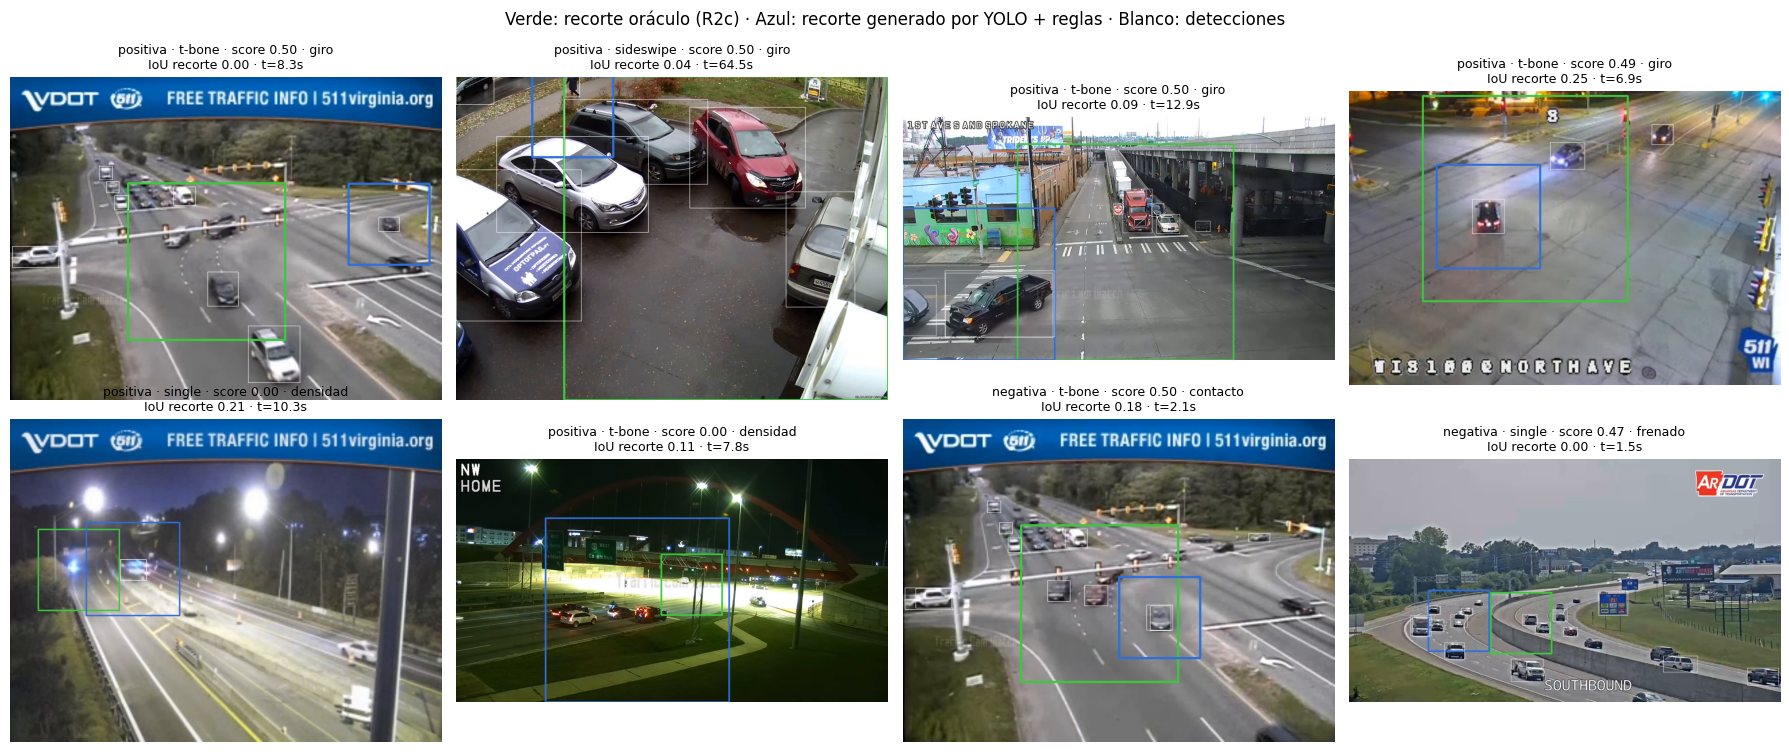

In [ ]:
# ===== 11. Figuras: ROI oráculo (verde) vs ROI YOLO (azul) en el momento del evento =====
import cv2, matplotlib.pyplot as plt
muestra = pd.concat([pos.sort_values('score', ascending=False).head(4), pos.sort_values('score').head(2),
                     neg.sort_values('score', ascending=False).head(2)]).drop_duplicates('wid')
fig, axs = plt.subplots(2, 4, figsize=(18, 7.5))
for ax, r in zip(axs.flat, muestra.itertuples()):
    t = r.t_evento if np.isfinite(r.t_evento) else (r.t_choque if r.y else (r.inicio + r.fin) / 2)
    cap = cv2.VideoCapture(r.ruta_local); cap.set(cv2.CAP_PROP_POS_MSEC, 1000 * t); ok, f = cap.read(); cap.release()
    if not ok: continue
    H, W = f.shape[:2]
    for caja, col in [(recorte(a_xyxy(r.roi_oraculo), W, H), (60, 200, 60)), (recorte((r.x1, r.y1, r.x2, r.y2), W, H), (219, 111, 47))]:
        cv2.rectangle(f, tuple(map(int, caja[:2])), tuple(map(int, caja[2:])), col, 4)
    for g in tracks[(tracks.wid == r.wid) & ((tracks.t - t).abs() < 0.06)].itertuples():
        cv2.rectangle(f, (int(g.x1 * W), int(g.y1 * H)), (int(g.x2 * W), int(g.y2 * H)), (255, 255, 255), 1)
    ax.imshow(f[..., ::-1]); ax.axis('off')
    ax.set_title(f'{r.clase} · {r.tipo_real} · score {r.score:.2f} · {r.fuente}\nIoU recorte {r.iou_recorte:.2f} · t={t:.1f}s', fontsize=9)
fig.suptitle('Verde: recorte oráculo (R2c) · Azul: recorte generado por YOLO + reglas · Blanco: detecciones', y=1.0)
fig.tight_layout(); fig.savefig(f'{SALIDA}/rois_yolo_vs_oraculo.png', dpi=130, bbox_inches='tight'); plt.show()

In [ ]:
# ===== 12. Guardar para R3b =====
cols = ['video', 'clase', 'inicio', 'fin', 'wid', 'roi', 'roi_yolo', 'score', 'alerta', 'fuente', 't_evento',
        'n_tracks', 'iou_recorte', 'choque_dentro']
out = d[cols].copy(); out['roi_yolo'] = out.roi_yolo.apply(lambda c: str(tuple(float(x) for x in c)))
out.to_csv(f'{SALIDA}/rois_yolo_{HUELLA}.csv', index=False)
resumen = dict(huella=HUELLA, yolo=YOLO_PESOS, fps=FPS_TRACK, imgsz=IMGSZ, formato_roi=FORMATO_ROI,
               auc_paso2=round(auc_p2, 3), alertas_pos=f'{pos.alerta.sum()}/{len(pos)}', alertas_neg=f'{neg.alerta.sum()}/{len(neg)}',
               choque_dentro=f'{pos.choque_dentro.sum()}/{len(pos)}', iou_recorte_mediana=round(pos.iou_recorte.median(), 3),
               bench=bench.to_dict('records'), reglas=REGLAS)
if t_frames is not None:
    resumen['ms_por_frame_con_tracking'] = round(1000 * float(np.mean(t_frames)), 2)
json.dump(resumen, open(f'{SALIDA}/resumen_r3a.json', 'w'), indent=1, ensure_ascii=False, default=str)
print('Guardado en', SALIDA, ':', sorted(os.listdir(SALIDA)))
print(json.dumps({k: v_ for k, v_ in resumen.items() if k not in ('bench', 'reglas')}, indent=1, ensure_ascii=False))

Guardado en /content/drive/MyDrive/roadvision/resultados_qwen/r3_ebfa594f : ['resumen_r3a.json', 'rois_yolo_ebfa594f.csv', 'rois_yolo_vs_oraculo.png', 'tracks_yolov8n_10fps.parquet']
{
 "huella": "ebfa594f",
 "yolo": "yolov8n.pt",
 "fps": 10,
 "imgsz": 640,
 "formato_roi": "xywh",
 "auc_paso2": 0.563,
 "alertas_pos": "5/30",
 "alertas_neg": "2/30",
 "choque_dentro": "16/30",
 "iou_recorte_mediana": 0.125,
 "ms_por_frame_con_tracking": 12.01
}
